# Lab 4 - Apache Spark w środowisku lokalnym

Mateusz Mróz, 251190

Spark 4.3.0 (PySpark) uruchomiony lokalnie na Windows 11: JDK 21 (Temurin), winutils (Hadoop), Python 3.12.
Dane: `trucks.csv`, `geolocation.csv` (Ćwiczenia 1-2) oraz NYC Yellow Taxi, styczeń 2024, Parquet (Ćwiczenie 3).

## 0. Konfiguracja

In [1]:
import os
import sys

# środowisko z instrukcji Lab 4 (C:\BigData); zmienne ustawiane tylko dla tego procesu
BIGDATA = r"C:\BigData"
os.environ["JAVA_HOME"] = rf"{BIGDATA}\jdk21"
os.environ["HADOOP_HOME"] = rf"{BIGDATA}\winutils"
os.environ["PATH"] = rf"{BIGDATA}\jdk21\bin;{BIGDATA}\winutils\bin;" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable

In [2]:
from pyspark.sql import SparkSession, Window, functions as F

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("lab4")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "| rdzenie:", spark.sparkContext.defaultParallelism)

Spark 4.3.0 | rdzenie: 20


## Ćwiczenia 1-2: ciężarówki i geolokalizacja

### Wczytanie i struktura danych

In [3]:
trucks = spark.read.csv("trucks.csv", header=True, inferSchema=True)
geo = spark.read.csv("geolocation.csv", header=True, inferSchema=True)

print("trucks:", trucks.count(), "wierszy,", len(trucks.columns), "kolumn")
print("geolocation:", geo.count(), "wierszy,", len(geo.columns), "kolumn")
geo.printSchema()
trucks.select(trucks.columns[:9]).show(5)
geo.show(5)

trucks: 100 wierszy, 111 kolumn
geolocation: 8000 wierszy, 10 kolumn
root
 |-- truckid: string (nullable = true)
 |-- driverid: string (nullable = true)
 |-- event: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- city: string (nullable = true)
 |-- state: string (nullable = true)
 |-- velocity: integer (nullable = true)
 |-- event_ind: integer (nullable = true)
 |-- idling_ind: integer (nullable = true)



+--------+-------+------------+-----------+---------+-----------+---------+-----------+---------+
|driverid|truckid|       model|jun13_miles|jun13_gas|may13_miles|may13_gas|apr13_miles|apr13_gas|
+--------+-------+------------+-----------+---------+-----------+---------+-----------+---------+
|      A1|     A1|Freightliner|       9217|     1914|       8769|     1892|      14234|     3008|
|      A2|     A2|        Ford|      12058|     2335|      14314|     2648|      11050|     2323|
|      A3|     A3|        Ford|      13652|     2899|      12075|     2603|      12277|     2792|
|      A4|     A4|    Kenworth|      12687|     2439|      10680|     2083|      11071|     2599|
|      A5|     A5|        Hino|      10233|     1825|      14634|     3450|       9281|     2028|
+--------+-------+------------+-----------+---------+-----------+---------+-----------+---------+
only showing top 5 rows
+-------+--------+---------+---------+-----------+----------+----------+--------+---------+---

In [4]:
# czy dane z obu plików da się połączyć po kierowcy?
drivers_without_trucks = (
    geo.select("driverid").distinct()
    .join(trucks.select("driverid"), "driverid", "left_anti")
)
print("kierowcy z geolocation bez wiersza w trucks:", drivers_without_trucks.count())
print("wiersze trucks z driverid != truckid:", trucks.filter("driverid != truckid").count())

geo.groupBy("event").count().orderBy(F.desc("count")).show(truncate=False)
trucks.groupBy("model").count().orderBy(F.desc("count")).show()
geo.select("latitude", "longitude", "velocity").summary("min", "mean", "max").show()

# długość -6.19 to nie Kalifornia: błąd geokodowania jednego miasta
geo.filter(F.col("longitude") > -100).groupBy("city", "longitude").count().show()

kierowcy z geolocation bez wiersza w trucks: 0


wiersze trucks z driverid != truckid: 0


+-------------------------+-----+
|event                    |count|
+-------------------------+-----+
|normal                   |7543 |
|lane departure           |152  |
|unsafe following distance|150  |
|overspeed                |90   |
|unsafe tail distance     |65   |
+-------------------------+-----+



+------------+-----+
|       model|count|
+------------+-----+
|        Ford|   20|
| Caterpillar|   19|
|   Peterbilt|   16|
|       Volvo|    9|
|    Navistar|    9|
|        Hino|    7|
|    Kenworth|    6|
|Freightliner|    5|
|     Oshkosh|    4|
|Western Star|    3|
|       Crane|    2|
+------------+-----+



+-------+-----------------+------------------+--------+
|summary|         latitude|         longitude|velocity|
+-------+-----------------+------------------+--------+
|    min|         32.61768|       -124.038407|       0|
|   mean|37.12894399500127|-118.6295509359972| 35.0565|
|    max|        41.526509|         -6.196595|     100|
+-------+-----------------+------------------+--------+



+------------+---------+-----+
|        city|longitude|count|
+------------+---------+-----+
|San Fernando|-6.196595|  156|
+------------+---------+-----+



### Transformacja trucks.csv: z formatu szerokiego na długi

Każdy wiersz `trucks.csv` to jedna ciężarówka i 54 miesiące (od `jan09` do `jun13`) zapisane jako pary kolumn `<miesiąc>_miles`, `<miesiąc>_gas`.
Do analizy przekształcamy to na jeden wiersz na ciężarówkę i miesiąc: `driverid, truckid, model, rdate, miles, gas, mpg`.

In [5]:
months = [c.removesuffix("_miles") for c in trucks.columns if c.endswith("_miles")]

stack_expr = "stack({}, {}) AS (rdate, miles, gas)".format(
    len(months), ", ".join(f"'{m}', {m}_miles, {m}_gas" for m in months)
)
truck_mileage = (
    trucks
    .selectExpr("driverid", "truckid", "model", stack_expr)
    .withColumn("rdate", F.to_date(F.concat(F.lit("01"), "rdate"), "ddMMMyy"))
    .withColumn("mpg", F.round(F.col("miles") / F.col("gas"), 2))
)
truck_mileage.createOrReplaceTempView("truck_mileage")

print("miesięcy:", len(months), "| wierszy po transformacji:", truck_mileage.count())
truck_mileage.printSchema()
truck_mileage.orderBy("driverid", "rdate").show(5)

miesięcy: 54 | wierszy po transformacji: 5400
root
 |-- driverid: string (nullable = true)
 |-- truckid: string (nullable = true)
 |-- model: string (nullable = true)
 |-- rdate: date (nullable = true)
 |-- miles: integer (nullable = true)
 |-- gas: integer (nullable = true)
 |-- mpg: double (nullable = true)



+--------+-------+------------+----------+-----+----+----+
|driverid|truckid|       model|     rdate|miles| gas| mpg|
+--------+-------+------------+----------+-----+----+----+
|      A1|     A1|Freightliner|2009-01-01|11176|2642|4.23|
|      A1|     A1|Freightliner|2009-02-01|13861|2642|5.25|
|      A1|     A1|Freightliner|2009-03-01| 9880|2642|3.74|
|      A1|     A1|Freightliner|2009-04-01|15276|2642|5.78|
|      A1|     A1|Freightliner|2009-05-01|12073|2642|4.57|
+--------+-------+------------+----------+-----+----+----+
only showing top 5 rows


### A. Łączny przebieg każdego kierowcy

In [6]:
total_miles = spark.sql("""
    SELECT driverid, SUM(miles) AS total_miles
    FROM truck_mileage
    GROUP BY driverid
    ORDER BY total_miles DESC
""")
total_miles.show(10)

+--------+-----------+
|driverid|total_miles|
+--------+-----------+
|     A52|     684131|
|     A80|     681115|
|     A94|     676750|
|      A5|     676574|
|     A10|     675377|
|     A24|     675334|
|     A68|     672089|
|     A71|     672026|
|     A27|     670601|
|     A31|     668620|
+--------+-----------+
only showing top 10 rows


### B. Średnie spalanie każdej ciężarówki

Dane mają przebieg (mile) i zużyte paliwo (galony) dla każdego miesiąca, więc spalanie liczymy jako mile na galon (MPG).
Poprawna średnia to suma mil podzielona przez sumę galonów (średnia ważona). Średnia z miesięcznych MPG daje każdemu miesiącowi tę samą wagę niezależnie od przebiegu.

Najpierw sprawdzamy, czy miesięczne `gas` to rzeczywiste pomiary.

In [7]:
# ile ciężarówek ma w danym roku to samo zużycie paliwa we wszystkich miesiącach?
spark.sql("""
    SELECT year,
           COUNT(*) AS trucks,
           SUM(CASE WHEN distinct_gas = 1 THEN 1 ELSE 0 END) AS trucks_with_constant_gas
    FROM (
        SELECT truckid, YEAR(rdate) AS year, COUNT(DISTINCT gas) AS distinct_gas
        FROM truck_mileage
        GROUP BY truckid, YEAR(rdate)
    )
    GROUP BY year
    ORDER BY year
""").show()

+----+------+------------------------+
|year|trucks|trucks_with_constant_gas|
+----+------+------------------------+
|2009|   100|                     100|
|2010|   100|                     100|
|2011|   100|                       0|
|2012|   100|                       0|
|2013|   100|                       0|
+----+------+------------------------+



W latach 2009-2010 każda ciężarówka ma tę samą wartość `gas` we wszystkich 12 miesiącach przy zmiennym przebiegu, więc to wypełniacz, a nie pomiar.
Miesięczne MPG z tych lat jest fikcyjne; rzetelne średnie spalanie liczymy z lat 2011-2013.

In [8]:
avg_mpg = spark.sql("""
    SELECT truckid, model,
           ROUND(SUM(miles) / SUM(gas), 2)                                    AS avg_mpg_all,
           ROUND(SUM(CASE WHEN YEAR(rdate) >= 2011 THEN miles END)
                 / SUM(CASE WHEN YEAR(rdate) >= 2011 THEN gas END), 2)        AS avg_mpg_2011_2013,
           ROUND(AVG(CASE WHEN YEAR(rdate) >= 2011 THEN mpg END), 2)          AS avg_of_monthly_mpg
    FROM truck_mileage
    GROUP BY truckid, model
    ORDER BY avg_mpg_2011_2013
""")
avg_mpg.show(10)

spark.sql("""
    SELECT model, COUNT(DISTINCT truckid) AS trucks, ROUND(SUM(miles) / SUM(gas), 2) AS avg_mpg_2011_2013
    FROM truck_mileage
    WHERE YEAR(rdate) >= 2011
    GROUP BY model
    ORDER BY avg_mpg_2011_2013
""").show()

+-------+------------+-----------+-----------------+------------------+
|truckid|       model|avg_mpg_all|avg_mpg_2011_2013|avg_of_monthly_mpg|
+-------+------------+-----------+-----------------+------------------+
|     A3|        Ford|       4.28|              4.6|              4.66|
|     A4|    Kenworth|       4.45|             4.61|              4.68|
|    A58|        Ford|       4.26|             4.65|              4.72|
|    A50|     Oshkosh|       4.47|             4.66|              4.71|
|    A65|        Hino|       4.54|             4.67|              4.72|
|    A95|   Peterbilt|        4.3|             4.68|              4.74|
|    A22| Caterpillar|       4.38|             4.68|              4.75|
|    A20|Western Star|       4.39|             4.69|              4.73|
|    A21|        Hino|       4.16|             4.69|              4.76|
|    A93|    Navistar|       4.32|              4.7|              4.76|
+-------+------------+-----------+-----------------+------------

+------------+------+-----------------+
|       model|trucks|avg_mpg_2011_2013|
+------------+------+-----------------+
|Western Star|     3|              4.9|
|    Kenworth|     6|             4.93|
|        Hino|     7|             4.96|
|    Navistar|     9|             4.96|
|Freightliner|     5|             4.96|
|   Peterbilt|    16|             4.97|
|     Oshkosh|     4|             4.98|
|        Ford|    20|             4.99|
| Caterpillar|    19|             5.01|
|       Volvo|     9|             5.03|
|       Crane|     2|              5.2|
+------------+------+-----------------+



### 3. Współczynnik ryzyka kierowcy

Zdarzenie niebezpieczne to każdy wpis z `event` innym niż `normal`. Współczynnik ryzyka = liczba zdarzeń / łączny przebieg kierowcy.
Dla czytelności dodana jest też liczba zdarzeń na 100 000 mil.

In [9]:
events = (
    geo.filter(F.col("event") != "normal")
    .groupBy("driverid")
    .agg(F.count("*").alias("events"))
)
riskfactor = (
    total_miles
    .join(events, "driverid", "left")
    .fillna({"events": 0})
    .withColumn("riskfactor", F.col("events") / F.col("total_miles"))
    .withColumn("events_per_100k_miles", F.round(F.col("riskfactor") * 100_000, 2))
    .orderBy(F.desc("riskfactor"))
)
riskfactor.show(10)

+--------+-----------+------+--------------------+---------------------+
|driverid|total_miles|events|          riskfactor|events_per_100k_miles|
+--------+-----------+------+--------------------+---------------------+
|     A97|     631199|    20|3.168572827270005E-5|                 3.17|
|     A73|     642222|    10|1.557093964392375E-5|                 1.56|
|     A35|     637069|     9|1.412719815279035...|                 1.41|
|     A50|     640069|     9|1.406098405015709...|                 1.41|
|      A5|     676574|     9|1.330231430708244...|                 1.33|
|     A95|     642920|     8|1.244322777328439E-5|                 1.24|
|     A71|     672026|     8|1.190430132167505...|                 1.19|
|     A92|     618049|     7|1.132596282818999...|                 1.13|
|     A86|     629558|     7|1.111891199857677...|                 1.11|
|     A44|     652599|     7|1.072634190368051...|                 1.07|
+--------+-----------+------+--------------------+-

In [10]:
import glob
import shutil

riskfactor.coalesce(1).write.mode("overwrite").csv("out/riskfactor", header=True)

# Spark zapisuje katalog z plikiem part-*.csv; kopiujemy go jako jeden plik riskfactor.csv
shutil.copy(glob.glob("out/riskfactor/part-*.csv")[0], "riskfactor.csv")
print(spark.read.csv("riskfactor.csv", header=True).count(), "wierszy w riskfactor.csv")

100 wierszy w riskfactor.csv


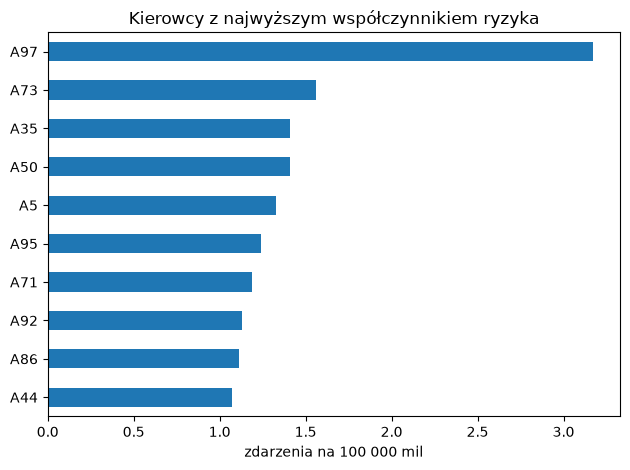

In [11]:
import matplotlib.pyplot as plt

top_risk = riskfactor.limit(10).toPandas()
ax = top_risk.plot.barh(x="driverid", y="events_per_100k_miles", legend=False,
                        title="Kierowcy z najwyższym współczynnikiem ryzyka")
ax.invert_yaxis()
ax.set_xlabel("zdarzenia na 100 000 mil")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("wykres1_riskfactor.png", dpi=150)
plt.show()

## Ćwiczenie 3: NYC Yellow Taxi (Parquet)

Plik `yellow_tripdata_2024-01.parquet` ze strony NYC TLC. Notebook pobiera go do `data/`, jeśli go tam nie ma.

### Podstawy i eksploracja (1-5)

In [12]:
import urllib.request

TLC = "https://d37ci6vzurychx.cloudfront.net"
TAXI = "data/yellow_tripdata_2024-01.parquet"
ZONES = "data/taxi_zone_lookup.csv"

os.makedirs("data", exist_ok=True)
for path, url in [(TAXI, f"{TLC}/trip-data/yellow_tripdata_2024-01.parquet"),
                  (ZONES, f"{TLC}/misc/taxi_zone_lookup.csv")]:
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)

# 1. wczytanie Parqueta (schemat jest zapisany w pliku)
taxi = spark.read.parquet(TAXI)

In [13]:
# 2. schemat i pierwsze 20 wierszy
taxi.printSchema()
taxi.show(20)

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)



+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+
|       2| 2024-01-01 00:57:55|  2024-01-01 01:17:43|              1|         1.72|         1|                 N|         186|          79|           2|       17.7|  1.0|    0.5|       0.

In [14]:
# 3. liczba rekordów
total_trips = taxi.count()
print("rekordów:", total_trips)

rekordów: 2964624


In [15]:
# 4. brakujące wartości w kluczowych kolumnach
key_cols = ["passenger_count", "trip_distance", "RatecodeID", "payment_type",
            "fare_amount", "total_amount", "congestion_surcharge", "Airport_fee"]
taxi.select([F.count_if(F.col(c).isNull()).alias(c) for c in key_cols]).show()

# braki występują razem: te same kursy nie mają passenger_count, RatecodeID i dopłat
taxi.filter(F.col("passenger_count").isNull()).groupBy("payment_type").count().show()

+---------------+-------------+----------+------------+-----------+------------+--------------------+-----------+
|passenger_count|trip_distance|RatecodeID|payment_type|fare_amount|total_amount|congestion_surcharge|Airport_fee|
+---------------+-------------+----------+------------+-----------+------------+--------------------+-----------+
|         140162|            0|    140162|           0|          0|           0|              140162|     140162|
+---------------+-------------+----------+------------+-----------+------------+--------------------+-----------+



+------------+------+
|payment_type| count|
+------------+------+
|           0|140162|
+------------+------+



In [16]:
# 5. statystyki opisowe
(
    taxi.select("total_amount", "trip_distance")
    .summary("mean", "min", "max", "stddev")
    .show()
)

+-------+------------------+------------------+
|summary|      total_amount|     trip_distance|
+-------+------------------+------------------+
|   mean|26.801504770952707|3.6521691789583146|
|    min|            -900.0|               0.0|
|    max|            5000.0|          312722.3|
| stddev|23.385577429672516|225.46257238220082|
+-------+------------------+------------------+



### Filtrowanie i transformacje (6-10)

In [17]:
# 6. tylko kursy z co najmniej jednym pasażerem
with_passengers = taxi.filter(F.col("passenger_count") > 0)
print("kursy z pasażerami:", with_passengers.count(), "z", total_trips)

kursy z pasażerami: 2792997 z 2964624


In [18]:
# 7. zerowy dystans, ale naliczona opłata
zero_distance = taxi.filter((F.col("trip_distance") == 0) & (F.col("fare_amount") > 0))
print("kursy 0 mil z opłatą > 0:", zero_distance.count())

kursy 0 mil z opłatą > 0: 56569


In [19]:
# 8. czas kursu w minutach; 9. średnia prędkość w mph
trips = (
    taxi
    .withColumn("trip_duration_minutes", F.round(
        F.timestamp_diff("SECOND", "tpep_pickup_datetime", "tpep_dropoff_datetime") / 60, 2))
    # try_divide zwraca NULL przy czasie 0 zamiast błędu (Spark 4 domyślnie ma tryb ANSI)
    .withColumn("average_speed", F.round(
        F.try_divide(F.col("trip_distance"), F.col("trip_duration_minutes") / 60), 2))
)
trips.select("tpep_pickup_datetime", "tpep_dropoff_datetime", "trip_distance",
             "trip_duration_minutes", "average_speed").show(5)
print("koniec przed początkiem:", trips.filter(F.col("trip_duration_minutes") < 0).count())

+--------------------+---------------------+-------------+---------------------+-------------+
|tpep_pickup_datetime|tpep_dropoff_datetime|trip_distance|trip_duration_minutes|average_speed|
+--------------------+---------------------+-------------+---------------------+-------------+
| 2024-01-01 00:57:55|  2024-01-01 01:17:43|         1.72|                 19.8|         5.21|
| 2024-01-01 00:03:00|  2024-01-01 00:09:36|          1.8|                  6.6|        16.36|
| 2024-01-01 00:17:06|  2024-01-01 00:35:01|          4.7|                17.92|        15.74|
| 2024-01-01 00:36:38|  2024-01-01 00:44:56|          1.4|                  8.3|        10.12|
| 2024-01-01 00:46:51|  2024-01-01 00:52:57|          0.8|                  6.1|         7.87|
+--------------------+---------------------+-------------+---------------------+-------------+
only showing top 5 rows


koniec przed początkiem: 56


In [20]:
# 10. usunięcie anomalii: ujemna kwota, koniec przed początkiem, data spoza stycznia 2024, brak pasażera
clean = (
    trips
    .filter(F.col("total_amount") >= 0)
    .filter(F.col("trip_duration_minutes") >= 0)
    .filter((F.col("tpep_pickup_datetime") >= "2024-01-01") & (F.col("tpep_pickup_datetime") < "2024-02-01"))
    .filter(F.col("passenger_count") > 0)
    .withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
).cache()

print("ujemna kwota:", taxi.filter(F.col("total_amount") < 0).count())
print("po czyszczeniu:", clean.count(), "z", total_trips)

ujemna kwota: 35504


po czyszczeniu: 2757476 z 2964624


### Agregacje i zapytania analityczne (11-17)

In [21]:
# 11. udział form płatności; 1 = karta kredytowa
payment_names = spark.createDataFrame(
    [(0, "Flex Fare / brak"), (1, "Credit card"), (2, "Cash"), (3, "No charge"),
     (4, "Dispute"), (5, "Unknown"), (6, "Voided trip")],
    ["payment_type", "payment_name"],
)
(
    taxi.groupBy("payment_type").count()
    .join(payment_names, "payment_type", "left")
    .withColumn("pct", F.round(F.col("count") * 100 / total_trips, 2))
    .orderBy("payment_type")
    .show()
)

+------------+-------+----------------+-----+
|payment_type|  count|    payment_name|  pct|
+------------+-------+----------------+-----+
|           0| 140162|Flex Fare / brak| 4.73|
|           1|2319046|     Credit card|78.22|
|           2| 439191|            Cash|14.81|
|           3|  19597|       No charge| 0.66|
|           4|  46628|         Dispute| 1.57|
+------------+-------+----------------+-----+



In [22]:
# 12. top 5 stref odbioru
zones = spark.read.csv(ZONES, header=True, inferSchema=True)
(
    taxi.groupBy("PULocationID").count()
    .join(zones, F.col("PULocationID") == F.col("LocationID"))
    .select("PULocationID", "Borough", "Zone", "count")
    .orderBy(F.desc("count"))
    .show(5, truncate=False)
)

+------------+---------+---------------------+------+
|PULocationID|Borough  |Zone                 |count |
+------------+---------+---------------------+------+
|132         |Queens   |JFK Airport          |145240|
|161         |Manhattan|Midtown Center       |143471|
|237         |Manhattan|Upper East Side South|142708|
|236         |Manhattan|Upper East Side North|136465|
|162         |Manhattan|Midtown East         |106717|
+------------+---------+---------------------+------+
only showing top 5 rows


In [23]:
# 13. średni napiwek wg liczby pasażerów (1, 2, 3, 4+)
(
    with_passengers
    .withColumn("passengers", F.when(F.col("passenger_count") >= 4, "4+")
                .otherwise(F.col("passenger_count").cast("string")))
    .groupBy("passengers")
    .agg(F.count("*").alias("trips"), F.round(F.avg("tip_amount"), 2).alias("avg_tip"))
    .orderBy("passengers")
    .show()
)

+----------+-------+-------+
|passengers|  trips|avg_tip|
+----------+-------+-------+
|         1|2188739|   3.37|
|         2| 405103|   3.72|
|         3|  91262|   3.54|
|        4+| 107893|   3.42|
+----------+-------+-------+



+----+------+
|hour| count|
+----+------+
|  18|197998|
|  17|193414|
|  16|180658|
+----+------+
only showing top 3 rows


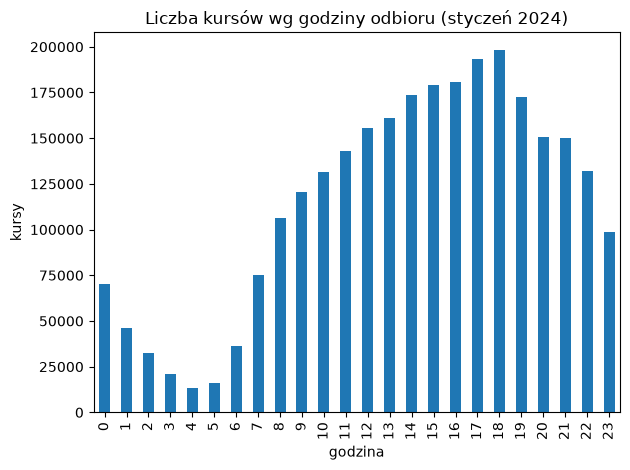

In [24]:
# 14. godzina szczytu
by_hour = (
    clean.groupBy(F.hour("tpep_pickup_datetime").alias("hour")).count()
    .orderBy("hour")
)
by_hour.orderBy(F.desc("count")).show(3)

hours = by_hour.toPandas()
ax = hours.plot.bar(x="hour", y="count", legend=False, title="Liczba kursów wg godziny odbioru (styczeń 2024)")
ax.set_xlabel("godzina")
ax.set_ylabel("kursy")
plt.tight_layout()
plt.savefig("wykres2_godziny.png", dpi=150)
plt.show()

In [25]:
# 15. przychód wg operatora (VendorID: 1 = Creative Mobile Technologies, 2 = Curb Mobility / VeriFone, 6 = Myle, 7 = Helix)
(
    taxi.groupBy("VendorID")
    .agg(F.count("*").alias("trips"), F.sum("total_amount").cast("decimal(14,2)").alias("revenue"))
    .orderBy("VendorID")
    .show()
)

+--------+-------+-----------+
|VendorID|  trips|    revenue|
+--------+-------+-----------+
|       1| 729732|18841261.98|
|       2|2234632|60602721.27|
|       6|    260|   12401.03|
+--------+-------+-----------+



In [26]:
# 16. korelacja dystans - napiwek
print("wszystkie kursy:       ", round(taxi.stat.corr("trip_distance", "tip_amount"), 4))
print("po czyszczeniu:        ", round(clean.stat.corr("trip_distance", "tip_amount"), 4))
# napiwki gotówkowe nie są rejestrowane, więc uczciwe porównanie tylko dla kart
card = clean.filter((F.col("payment_type") == 1) & (F.col("trip_distance").between(0.1, 100)))
print("karta, dystans 0,1-100:", round(card.stat.corr("trip_distance", "tip_amount"), 4))

wszystkie kursy:        0.0112


po czyszczeniu:         0.2103


karta, dystans 0,1-100:

 0.7264


In [27]:
# 17. napiwek jako procent całej opłaty (kursy płacone kartą)
tips = (
    clean.filter((F.col("payment_type") == 1) & (F.col("total_amount") > 0))
    .withColumn("tip_percentage", F.round(F.col("tip_amount") * 100 / F.col("total_amount"), 2))
)
tips.select("trip_distance", "tip_amount", "total_amount", "tip_percentage").show(5)
tips.select(
    F.round(F.avg("tip_percentage"), 2).alias("avg_tip_pct"),
    F.percentile("tip_percentage", 0.5).alias("median_tip_pct"),
).show()

+-------------+----------+------------+--------------+
|trip_distance|tip_amount|total_amount|tip_percentage|
+-------------+----------+------------+--------------+
|          1.8|      3.75|       18.75|          20.0|
|          4.7|       3.0|        31.3|          9.58|
|          1.4|       2.0|        17.0|         11.76|
|          0.8|       3.2|        16.1|         19.88|
|          4.7|       6.9|        41.5|         16.63|
+-------------+----------+------------+--------------+
only showing top 5 rows


+-----------+--------------+
|avg_tip_pct|median_tip_pct|
+-----------+--------------+
|      14.78|         16.67|
+-----------+--------------+



### Operacje zaawansowane i zapis (18-20)

In [28]:
# 18. najdłuższy kurs dla każdego dnia tygodnia (funkcja okna)
def longest_per_weekday(df):
    w = Window.partitionBy("day_of_week").orderBy(F.desc("trip_distance"))
    return (
        df
        .withColumn("day_no", F.dayofweek("tpep_pickup_datetime"))
        .withColumn("day_of_week", F.date_format("tpep_pickup_datetime", "EEEE"))
        .withColumn("rn", F.row_number().over(w))
        .filter("rn = 1")
        .select("day_of_week", "tpep_pickup_datetime", "trip_distance",
                "trip_duration_minutes", "average_speed", "total_amount")
        .orderBy("day_no")
    )

longest_per_weekday(clean).show(truncate=False)

+-----------+--------------------+-------------+---------------------+-------------+------------+
|day_of_week|tpep_pickup_datetime|trip_distance|trip_duration_minutes|average_speed|total_amount|
+-----------+--------------------+-------------+---------------------+-------------+------------+
|Sunday     |2024-01-14 17:22:52 |1715.22      |42.38                |2428.34      |98.88       |
|Monday     |2024-01-22 16:40:43 |157.25       |150.62               |62.64        |900.0       |
|Tuesday    |2024-01-02 08:13:18 |971.8        |90.2                 |646.43       |23.0        |
|Wednesday  |2024-01-17 14:50:40 |15400.32     |32.13                |28758.77     |39.48       |
|Thursday   |2024-01-11 12:25:11 |176.43       |23.12                |457.86       |52.63       |
|Friday     |2024-01-12 10:40:28 |210.82       |186.47               |67.84        |515.88      |
|Saturday   |2024-01-06 21:01:38 |142.62       |160.1                |53.45        |940.93      |
+-----------+-------

Część „najdłuższych” kursów to błędy taksometru: tysiące mil w kilkadziesiąt minut. Dodatkowy filtr wiarygodności: średnia prędkość do 80 mph.

In [29]:
longest_per_weekday(clean.filter(F.col("average_speed") <= 80)).show(truncate=False)

+-----------+--------------------+-------------+---------------------+-------------+------------+
|day_of_week|tpep_pickup_datetime|trip_distance|trip_duration_minutes|average_speed|total_amount|
+-----------+--------------------+-------------+---------------------+-------------+------------+
|Sunday     |2024-01-14 15:49:26 |122.47       |131.02               |56.08        |758.89      |
|Monday     |2024-01-22 16:40:43 |157.25       |150.62               |62.64        |900.0       |
|Tuesday    |2024-01-02 07:50:08 |233.25       |219.35               |63.8         |1617.5      |
|Wednesday  |2024-01-24 04:31:22 |155.56       |140.93               |66.23        |494.38      |
|Thursday   |2024-01-18 11:45:51 |97.5         |121.82               |48.02        |450.2       |
|Friday     |2024-01-12 10:40:28 |210.82       |186.47               |67.84        |515.88      |
|Saturday   |2024-01-06 21:01:38 |142.62       |160.1                |53.45        |940.93      |
+-----------+-------

In [30]:
# 19. oczyszczone dane z czasem kursu -> Parquet partycjonowany po dacie kursu
clean.write.mode("overwrite").partitionBy("pickup_date").parquet("out/taxi_clean_parquet")

clean_back = spark.read.parquet("out/taxi_clean_parquet")
print("wierszy:", clean_back.count(), "| partycji:", len(glob.glob("out/taxi_clean_parquet/pickup_date=*")))
print(sorted(os.listdir("out/taxi_clean_parquet"))[:3])

wierszy: 2757476 | partycji: 31
['._SUCCESS.crc', '_SUCCESS', 'pickup_date=2024-01-01']


In [31]:
# 20. dzienny przychód -> ORC
daily_revenue = (
    clean.groupBy("pickup_date")
    .agg(
        F.count("*").alias("trips"),
        F.round(F.sum("total_amount"), 2).alias("revenue"),
        F.round(F.avg("total_amount"), 2).alias("avg_fare"),
    )
    .orderBy("pickup_date")
)
daily_revenue.coalesce(1).write.mode("overwrite").orc("out/daily_revenue_orc")
spark.read.orc("out/daily_revenue_orc").orderBy("pickup_date").show(31)

+-----------+------+----------+--------+
|pickup_date| trips|   revenue|avg_fare|
+-----------+------+----------+--------+
| 2024-01-01| 68559|2155534.84|   31.44|
| 2024-01-02| 71581|2228150.82|   31.13|
| 2024-01-03| 78546|2308511.37|   29.39|
| 2024-01-04| 97894|2731546.39|    27.9|
| 2024-01-05| 97640|2648611.63|   27.13|
| 2024-01-06| 89771|2322172.14|   25.87|
| 2024-01-07| 63341|1845539.91|   29.14|
| 2024-01-08| 76014| 2162897.5|   28.45|
| 2024-01-09| 84662|2196479.29|   25.94|
| 2024-01-10| 89984|2467622.61|   27.42|
| 2024-01-11| 99350|2811318.99|    28.3|
| 2024-01-12| 96943|2744448.71|   28.31|
| 2024-01-13| 97674|2532393.36|   25.93|
| 2024-01-14| 86729|2334639.49|   26.92|
| 2024-01-15| 72406|2089636.31|   28.86|
| 2024-01-16| 85638|2488385.78|   29.06|
| 2024-01-17|100112|2769177.45|   27.66|
| 2024-01-18|102126|2791470.31|   27.33|
| 2024-01-19| 89727|2378120.15|    26.5|
| 2024-01-20| 97914|2407340.57|   24.59|
| 2024-01-21| 77178|2143782.35|   27.78|
| 2024-01-22| 80

In [32]:
# porównanie rozmiarów: ten sam dzienny raport jako CSV, Parquet i ORC; oryginał Parquet vs CSV
def dir_size(path):
    if os.path.isfile(path):
        return os.path.getsize(path)
    return sum(os.path.getsize(os.path.join(d, f)) for d, _, fs in os.walk(path) for f in fs if not f.endswith(".crc"))

daily_revenue.coalesce(1).write.mode("overwrite").csv("out/daily_revenue_csv", header=True)
daily_revenue.coalesce(1).write.mode("overwrite").parquet("out/daily_revenue_parquet")
taxi.limit(200_000).coalesce(1).write.mode("overwrite").csv("out/taxi_200k_csv", header=True)
taxi.limit(200_000).coalesce(1).write.mode("overwrite").parquet("out/taxi_200k_parquet")
taxi.limit(200_000).coalesce(1).write.mode("overwrite").orc("out/taxi_200k_orc")

for p in ["out/daily_revenue_csv", "out/daily_revenue_parquet", "out/daily_revenue_orc",
          "out/taxi_200k_csv", "out/taxi_200k_parquet", "out/taxi_200k_orc"]:
    print(f"{p:28s} {dir_size(p) / 1024:10.1f} KB")

out/daily_revenue_csv               1.1 KB
out/daily_revenue_parquet           1.9 KB
out/daily_revenue_orc               1.2 KB
out/taxi_200k_csv               21572.6 KB
out/taxi_200k_parquet            4238.9 KB
out/taxi_200k_orc                3835.4 KB


In [33]:
spark.stop()